In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

deliveries = pd.read_csv("deliveries.csv")
pd.read_csv("deliveries.csv")

,record_id,month,route_id,hub,promised_days,actual_days
0,1,Jan,R1,Mumbai,2,2
1,2,Jan,R2,Chennai,3,4
2,3,Jan,R3,Delhi,5,8
3,4,Jan,R4,Mumbai,6,10
4,5,Feb,R1,Chennai,2,5
5,6,Feb,R2,Delhi,3,3
6,7,Feb,R3,Delhi,5,10
7,8,Feb,R4,Chennai,6,7
8,9,Mar,R1,Delhi,2,8
9,10,Mar,R2,Mumbai,3,5


In [3]:
routes = pd.read_csv("routes.csv")
pd.read_csv("routes.csv")

,route_id,route,service_type
0,R1,Metro Link,Express
1,R2,City Dash,Express
2,R3,Highway Freight,Standard
3,R4,Rural Feeder,Standard


In [13]:
deliveries = deliveries.drop_duplicates()
print("After row count:", len(deliveries))       # 12

df = deliveries.merge(routes, on="route_id", how="left")

assert len(df) == 12
assert df["service_type"].isna().sum() == 0
print("✅ 12 rows and zero unmatched route_id")
df

After row count: 12
✅ 12 rows and zero unmatched route_id


,record_id,month,route_id,hub,promised_days,actual_days,route,service_type
0,1,Jan,R1,Mumbai,2,2,Metro Link,Express
1,2,Jan,R2,Chennai,3,4,City Dash,Express
2,3,Jan,R3,Delhi,5,8,Highway Freight,Standard
3,4,Jan,R4,Mumbai,6,10,Rural Feeder,Standard
4,5,Feb,R1,Chennai,2,5,Metro Link,Express
5,6,Feb,R2,Delhi,3,3,City Dash,Express
6,7,Feb,R3,Delhi,5,10,Highway Freight,Standard
7,8,Feb,R4,Chennai,6,7,Rural Feeder,Standard
8,9,Mar,R1,Delhi,2,8,Metro Link,Express
9,10,Mar,R2,Mumbai,3,5,City Dash,Express


In [14]:
df["delay_days"] = (df["actual_days"] - df["promised_days"]).clip(lower=0)
df

,record_id,month,route_id,hub,promised_days,actual_days,route,service_type,delay_days
0,1,Jan,R1,Mumbai,2,2,Metro Link,Express,0
1,2,Jan,R2,Chennai,3,4,City Dash,Express,1
2,3,Jan,R3,Delhi,5,8,Highway Freight,Standard,3
3,4,Jan,R4,Mumbai,6,10,Rural Feeder,Standard,4
4,5,Feb,R1,Chennai,2,5,Metro Link,Express,3
5,6,Feb,R2,Delhi,3,3,City Dash,Express,0
6,7,Feb,R3,Delhi,5,10,Highway Freight,Standard,5
7,8,Feb,R4,Chennai,6,7,Rural Feeder,Standard,1
8,9,Mar,R1,Delhi,2,8,Metro Link,Express,6
9,10,Mar,R2,Mumbai,3,5,City Dash,Express,2


In [15]:
grp = df.groupby("service_type")
summary = pd.DataFrame({
    "total_delay_days": grp["delay_days"].sum(),
    "total_records": grp["record_id"].count(),
    "delayed_records": (df["actual_days"] > df["promised_days"]).groupby(df["service_type"]).sum(),
}).reset_index()

summary["delay_incidence_rate_pct"] = (
    summary["delayed_records"] / summary["total_records"] * 100
).round(2)
summary = summary.sort_values("total_delay_days", ascending=False).reset_index(drop=True)
print(summary)

#Largest delay single route and its share
route_delay = df.groupby("route")["delay_days"].sum()
top_route = route_delay.idxmax()
top_route_delay = int(route_delay.max())
total_delay = int(df["delay_days"].sum())
top_route_share = round(top_route_delay / total_delay * 100, 2)

print(f"\nTop route: {top_route}")
print(f"Top route summed delay_days: {top_route_delay}")
print(f"Overall total delay_days: {total_delay}")
print(f"Top route share of total delay: {top_route_share}%")

  service_type  total_delay_days  total_records  delayed_records  \
0     Standard                22              6                5   
1      Express                12              6                4   

   delay_incidence_rate_pct  
0                     83.33  
1                     66.67  

Top route: Rural Feeder
Top route summed delay_days: 14
Overall total delay_days: 34
Top route share of total delay: 41.18%


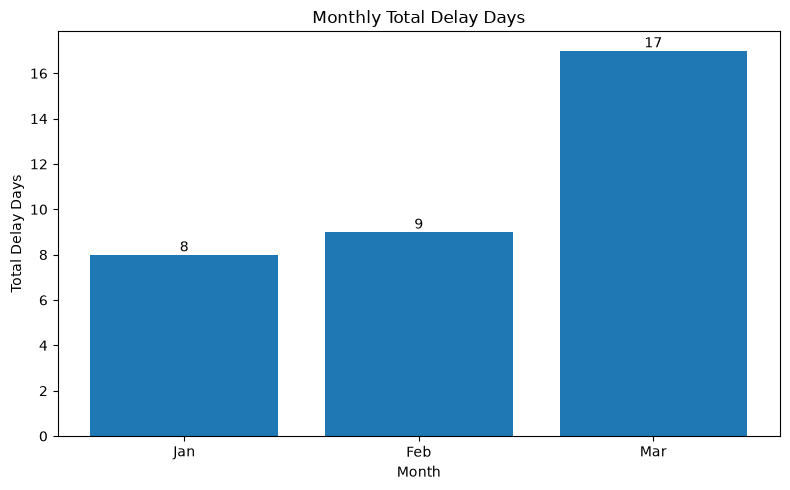

In [16]:
monthly = df.groupby("month")["delay_days"].sum().reindex(["Jan", "Feb", "Mar"])
os.makedirs("outputs", exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(monthly.index, monthly.values)
ax.bar_label(bars)
ax.set_title("Monthly Total Delay Days")
ax.set_xlabel("Month")
ax.set_ylabel("Total Delay Days")
plt.tight_layout()
plt.savefig("outputs/python_chart.png", dpi=150)
plt.show()

In [17]:
df.to_csv("outputs/clean_data.csv", index=False)
summary.to_csv("outputs/python_summary.csv", index=False)
print("Saved files:", sorted(os.listdir("outputs")))

Saved files: ['clean_data.csv', 'python_chart.png', 'python_summary.csv']
